Complete the exercises below For **Assignment #11**.

For this assignment we'll use the [California Housing Data](https://inria.github.io/scikit-learn-mooc/python_scripts/datasets_california_housing.html).

This data is available in the [Scikit-Learn](https://scikit-learn.org/stable/index.html) Python module.

To retrieve the data,
1. open a new Python notebook, and,
2. run the following code.

```python
from sklearn.datasets import fetch_california_housing

california_housing = fetch_california_housing(as_frame=True)

(
    california_housing.data
    .assign(MedianHouseValue=california_housing.target)
    .to_csv('california-housing.csv', index=False)
)
```

This will produce a new file called `california-housing.csv` that we'll import in this notebook.

Back in the Python notebook, you can use the following snippet to get a description of the dataset.

```python
print(california_housing.DESCR)
```


Load the `tidymodels` package.

In [4]:

library(tidymodels)


-- Attaching packages -------------------------------------- tidymodels 1.4.1 --

v broom        1.0.13     v recipes      1.3.3 
v dials        1.4.4      v rsample      1.3.2 
v dplyr        1.2.1      v tailor       0.1.0 
v ggplot2      4.0.3      v tidyr        1.3.2 
v infer        1.1.0      v tune         2.1.0 
v modeldata    1.5.1      v workflows    1.3.0 
v parsnip      1.6.0      v workflowsets 1.1.1 
v purrr        1.2.2      v yardstick    1.4.0 

-- Conflicts ----------------------------------------- tidymodels_conflicts() --
x purrr::discard() masks scales::discard()
x dplyr::filter()  masks stats::filter()
x dplyr::lag()     masks stats::lag()
x purrr::map()     masks maps::map()
x recipes::step()  masks stats::step()



Run the following cell to read in our data.

In [5]:
housing = readr::read_csv('california-housing.csv', col_types = readr::cols())

housing |> head()

MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
8.3252,41,6.984127,1.0238095,322,2.555556,37.88,-122.23,4.526
8.3014,21,6.238137,0.9718805,2401,2.109842,37.86,-122.22,3.585
7.2574,52,8.288136,1.0734463,496,2.802260,37.85,-122.24,3.521
5.6431,52,5.817352,1.0730594,558,2.547945,37.85,-122.25,3.413
3.8462,52,6.281853,1.0810811,565,2.181467,37.85,-122.25,3.422
4.0368,52,4.761658,1.1036269,413,2.139896,37.85,-122.25,2.697


Let's build a random forest model to predict `MedianHouseValue`.

1. Create your model, set the engine to `ranger` with `importance = 'impurity'` and the mode as `regression`.
2. Fit the model using `MedianHouseValue` as the response variable and all other columns as predictors.

In [6]:
set.seed(123)

rf_model <- rand_forest() |>
  set_engine("ranger", importance = "impurity") |>
  set_mode("regression")

rf_fit <- rf_model |>
  fit(MedianHouseValue ~ ., data = housing)

rf_fit



parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = ~"impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      20640 
Number of independent variables:  8 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        variance 
OOB prediction error (MSE):       0.2318938 
R squared (OOB):                  0.8258552 

❓ What is the OOB error for this model?

**Answer:** 0.2319 (mean squared error) see below code. The out-of-bag prediction error for the random forest model is approximately 0.2319 MSE. This measures the model’s average squared prediction error on observations excluded from each bootstrap sample.

In [7]:
oob_error <- rf_fit |>
  extract_fit_engine() |>
  pluck("prediction.error")

oob_error



[1] 0.2318938

Plot the feature importances using the `vip` package. Remember that you can use the `extract_fit_engine` function to get the `ranger` model object to send to the `vip` function.


Attaching package: 'vip'


The following object is masked from 'package:utils':

    vi




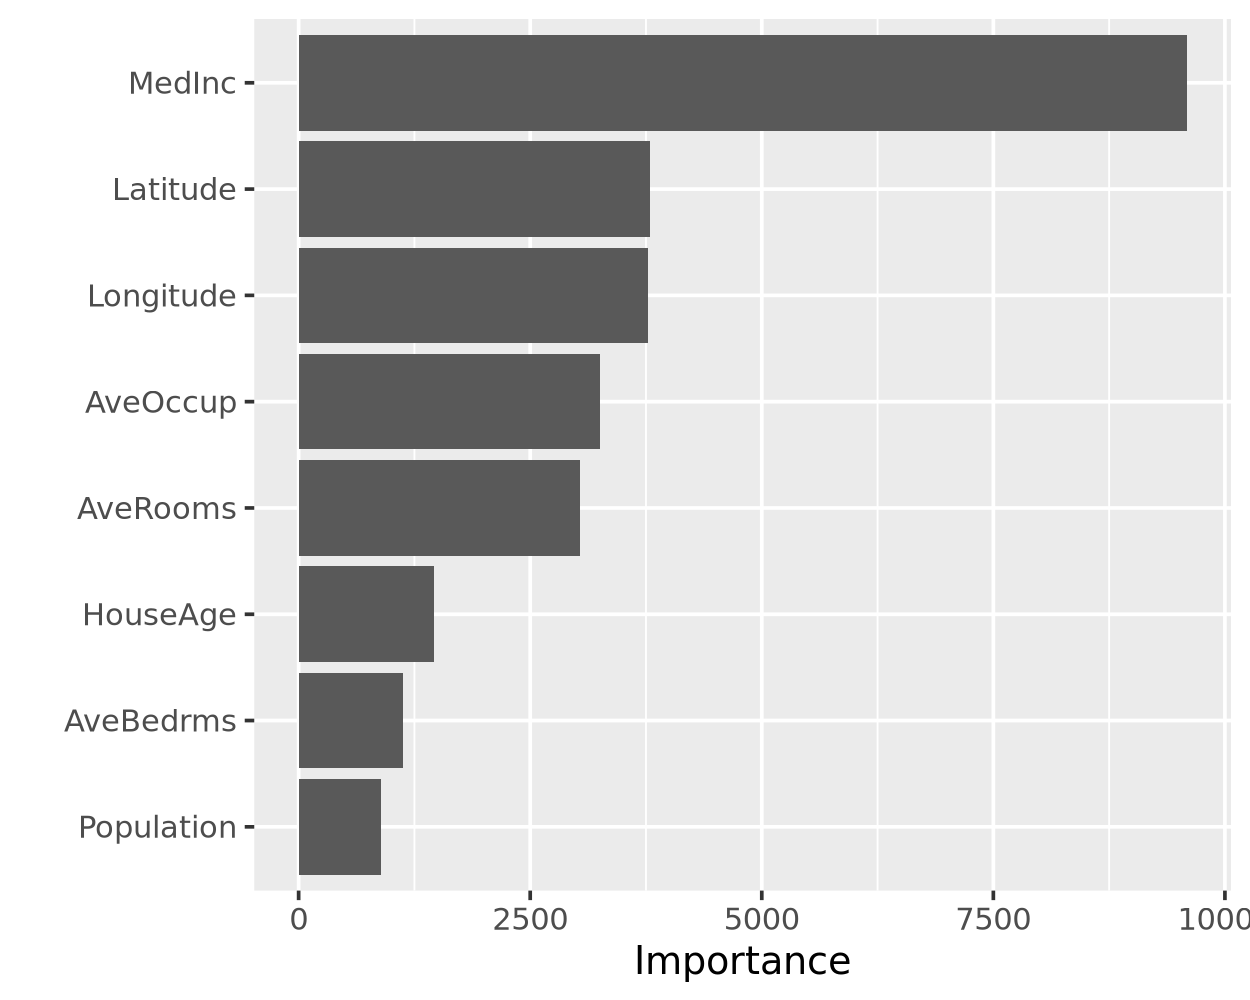

In [8]:
library(vip)

rf_fit |>
  extract_fit_engine() |>
  vip()



It looks like `Latitude` and `Longitude` are important for predicting home value. Let's explore those variables.

Install the `mapdata` package into your project environment.

1. Open a Terminal, and,
2. Run the following command:

```bash
pixi add r-mapdata
```

Load the `mapdata` package.

In [6]:
install.packages("mapdata", repos = "https://cloud.r-project.org")

also installing the dependency 'maps'


Warning message in install.packages("mapdata", repos = "https://cloud.r-project.org"):
"installation of package 'maps' had non-zero exit status"
Warning message in install.packages("mapdata", repos = "https://cloud.r-project.org"):
"installation of package 'mapdata' had non-zero exit status"
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [9]:
library(tidyverse)
library(mapdata)




-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v forcats   1.0.1     v stringr   1.6.0
v lubridate 1.9.5     v tibble    3.3.1
v readr     2.2.0     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x readr::col_factor() masks scales::col_factor()
x purrr::discard()    masks scales::discard()
x dplyr::filter()     masks stats::filter()
x stringr::fixed()    masks recipes::fixed()
x dplyr::lag()        masks stats::lag()
x purrr::map()        masks maps::map()
x readr::spec()       masks yardstick::spec()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


The following code will generate a map of California. Adapt this code to plot `Latitude` and `Longitude` from the `housing` dataset, color points by the `MedianHouseValue`. [Here is an example for reference](https://raw.githubusercontent.com/UNC-DATA-730/a10/main/example.png).


```r
california = map_data("state") |> filter(region == 'california')

ggplot(data = california) + 
    geom_polygon(aes(x = long, y = lat), fill = "grey90", color = "grey40") +
    coord_quickmap() +
    theme_void()
```

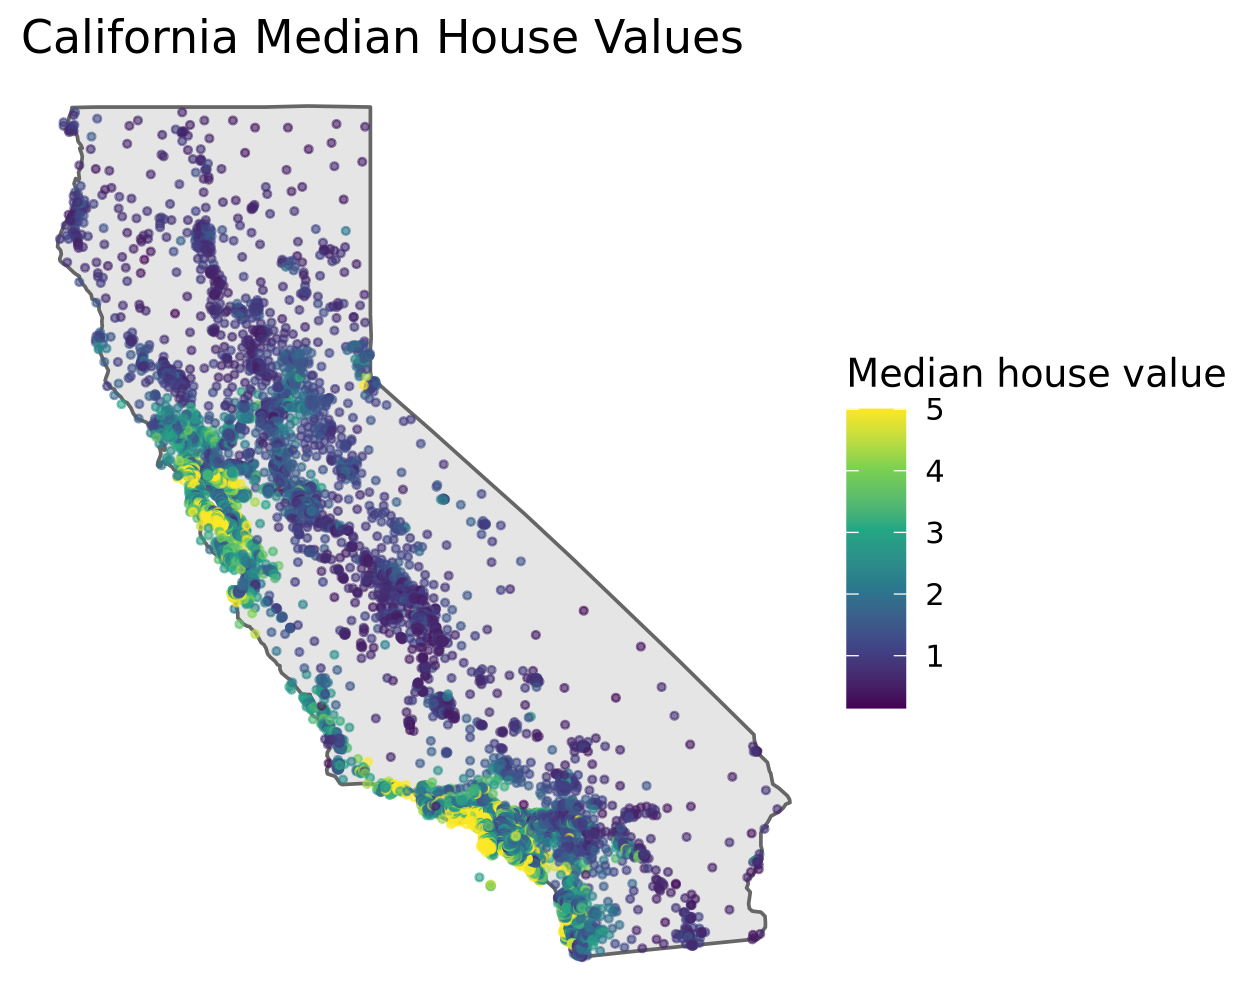

In [10]:
california <- map_data("state") |>
  filter(region == "california")

ggplot(data = california) +
  geom_polygon(
    aes(x = long, y = lat, group = group),
    fill = "grey90",
    color = "grey40"
  ) +
  geom_point(
    data = housing,
    aes(
      x = Longitude,
      y = Latitude,
      color = MedianHouseValue
    ),
    size = 0.7,
    alpha = 0.6
  ) +
  scale_color_viridis_c(name = "Median house value") +
  coord_quickmap() +
  labs(
    title = "California Median House Values",
    x = "Longitude",
    y = "Latitude"
  ) +
  theme_void()

